### Basic Statistics
#### Descriptive Analytics and Data Preprocessing on Sales & Discounts Dataset

#### Firstly we will import all the libraries and load the dataset of sales and discount 

In [1]:
#Importing all the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as stat


In [2]:
#Loading the dataset using pandas
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\sales_data_with_discounts.csv")

In [3]:
# preview dataframe
df.head()

,Date,Day,SKU,City,Volume,BU,Brand,Model,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
0,01-04-2021,Thursday,M01,C,15,Mobiles,RealU,RU-10,12100,181500,11.654820,21153.498820,160346.501180
1,01-04-2021,Thursday,M02,C,10,Mobiles,RealU,RU-9 Plus,10100,101000,11.560498,11676.102961,89323.897039
2,01-04-2021,Thursday,M03,C,7,Mobiles,YouM,YM-99,16100,112700,9.456886,10657.910157,102042.089843
3,01-04-2021,Thursday,M04,C,6,Mobiles,YouM,YM-99 Plus,20100,120600,6.935385,8364.074702,112235.925298
4,01-04-2021,Thursday,M05,C,3,Mobiles,YouM,YM-98,8100,24300,17.995663,4372.946230,19927.053770


#### Descriptive Analytics for Numerical Columns

In [4]:
df.info() # we use .info so we can identify all the numerical type columns that is integer and float type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               450 non-null    object 
 1   Day                450 non-null    object 
 2   SKU                450 non-null    object 
 3   City               450 non-null    object 
 4   Volume             450 non-null    int64  
 5   BU                 450 non-null    object 
 6   Brand              450 non-null    object 
 7   Model              450 non-null    object 
 8   Avg Price          450 non-null    int64  
 9   Total Sales Value  450 non-null    int64  
 10  Discount Rate (%)  450 non-null    float64
 11  Discount Amount    450 non-null    float64
 12  Net Sales Value    450 non-null    float64
dtypes: float64(3), int64(3), object(7)
memory usage: 45.8+ KB


In [5]:
### we get that columns which are numerical  - "Volume","Avg Price", "Total Sales Value","Discount Rate (%)","Discount ammount","Net Sales Value" 

In [6]:
# Now we pull those columns
numerical_colms = ["Volume","Avg Price", "Total Sales Value","Discount Rate (%)","Discount Amount","Net Sales Value"]
df[numerical_colms]


,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
0,15,12100,181500,11.654820,21153.498820,160346.501180
1,10,10100,101000,11.560498,11676.102961,89323.897039
2,7,16100,112700,9.456886,10657.910157,102042.089843
3,6,20100,120600,6.935385,8364.074702,112235.925298
4,3,8100,24300,17.995663,4372.946230,19927.053770
...,...,...,...,...,...,...
445,2,1300,2600,15.475687,402.367873,2197.632127
446,6,2600,15600,17.057027,2660.896242,12939.103758
447,2,1600,3200,18.965550,606.897606,2593.102394
448,3,1900,5700,16.793014,957.201826,4742.798174


##### Now lets print the mean, median, mode and standard deviation for these columns 

In [7]:
mean_1  = df[numerical_colms].mean()
median_1 = df[numerical_colms].median()
mode_1 = df[numerical_colms].mode()
sd_1 = df[numerical_colms].std()

print("Mean of numerical data\n",mean_1)
print("Median of numerical data\n",median_1)
print("Mode of numerical data\n",mode_1)
print("Standard Deviation of numerical data\n",sd_1)

Mean of numerical data
 Volume                   5.066667
Avg Price            10453.433333
Total Sales Value    33812.835556
Discount Rate (%)       15.155242
Discount Amount       3346.499424
Net Sales Value      30466.336131
dtype: float64
Median of numerical data
 Volume                  4.000000
Avg Price            1450.000000
Total Sales Value    5700.000000
Discount Rate (%)      16.577766
Discount Amount       988.933733
Net Sales Value      4677.788059
dtype: float64
Mode of numerical data
      Volume  Avg Price  Total Sales Value  Discount Rate (%)  Discount Amount  \
0       3.0      400.0            24300.0           5.007822        69.177942   
1       NaN      450.0                NaN           5.055218        73.025199   
2       NaN      500.0                NaN           5.059801        93.649161   
3       NaN     1300.0                NaN           5.072124        94.682735   
4       NaN     8100.0                NaN           5.084108       102.705757   
..      

In [8]:
summary_table = pd.DataFrame({ "Mean": df[numerical_colms].mean(),
                               "Median": df[numerical_colms].median(),
                               "Mode": df[numerical_colms].mode().iloc[0],
                               "Standard Deviation": df[numerical_colms].std()
})
# sice we have multiple modes for the summary table we are using .iloc function to use only the first modal value 
print(summary_table)

                           Mean       Median          Mode  Standard Deviation
Volume                 5.066667     4.000000      3.000000            4.231602
Avg Price          10453.433333  1450.000000    400.000000        18079.904840
Total Sales Value  33812.835556  5700.000000  24300.000000        50535.074173
Discount Rate (%)     15.155242    16.577766      5.007822            4.220602
Discount Amount     3346.499424   988.933733     69.177942         4509.902963
Net Sales Value    30466.336131  4677.788059    326.974801        46358.656624


##### Interpretation of the statistics
* For Volume Mean is a bit over median suggesting some skewness
* For Avg Price mean is way larger that the media suggesting outliers are present int the dataset
* for Total Sales Value Mean is also larger the the median hence it is highly skewed as well
* For Discount rate mean and median are pretty simillar indicating no skewness
* for discount amount Mean is much higher than median, showing that a few transactions received very high discounts
* For Net Sles Value high mean value indicates few high value transactions affecting the average 

#### Data Visualisation

#### Histograms for checking distributions of each numerical column 

In [10]:
## First make a new data frame consisting of only numerical columns 
df_num = pd.DataFrame(df[numerical_colms])
df_num

,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
0,15,12100,181500,11.654820,21153.498820,160346.501180
1,10,10100,101000,11.560498,11676.102961,89323.897039
2,7,16100,112700,9.456886,10657.910157,102042.089843
3,6,20100,120600,6.935385,8364.074702,112235.925298
4,3,8100,24300,17.995663,4372.946230,19927.053770
...,...,...,...,...,...,...
445,2,1300,2600,15.475687,402.367873,2197.632127
446,6,2600,15600,17.057027,2660.896242,12939.103758
447,2,1600,3200,18.965550,606.897606,2593.102394
448,3,1900,5700,16.793014,957.201826,4742.798174


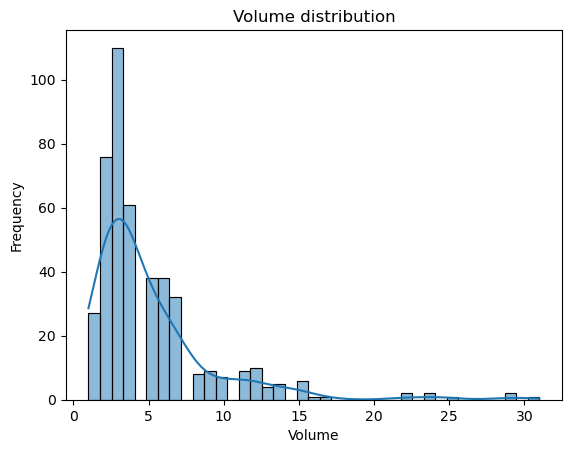

In [12]:
sns.histplot(data=df_num, x="Volume", kde=True)
plt.ylabel("Frequency")
plt.title("Volume distribution")   
plt.show()

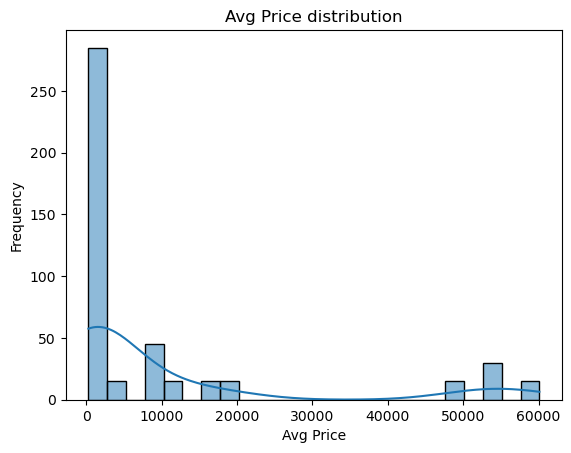

In [23]:
# Average Price
sns.histplot(data=df_num, x="Avg Price", kde=True)
plt.ylabel("Frequency")
plt.title("Avg Price distribution")   
plt.show()

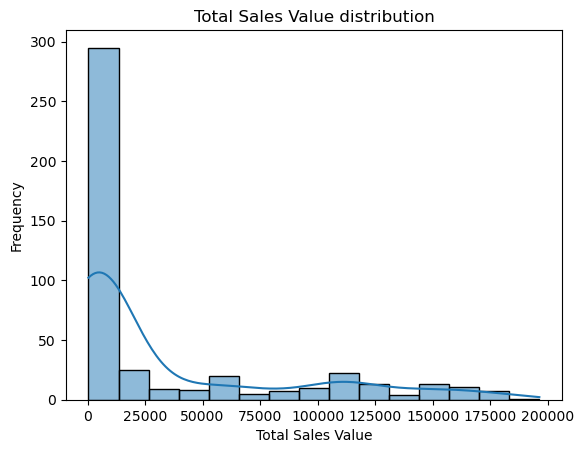

In [22]:
## Total Sales Value
sns.histplot(data=df_num, x="Total Sales Value", kde=True)
plt.ylabel("Frequency")
plt.title("Total Sales Value distribution")   
plt.show()

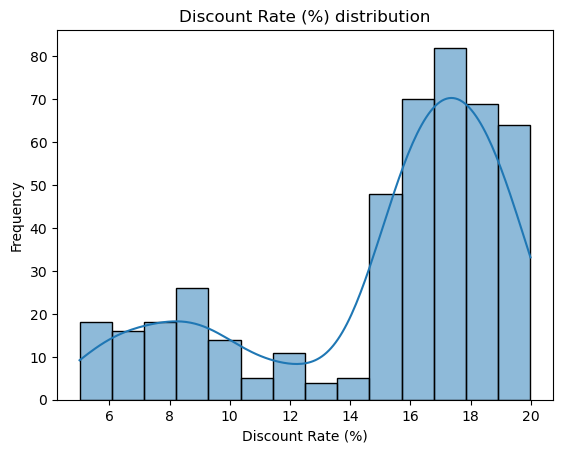

In [21]:
#Discount Rate (%)
sns.histplot(data=df_num, x="Discount Rate (%)", kde=True)
plt.ylabel("Frequency")
plt.title("Discount Rate (%) distribution")   
plt.show()

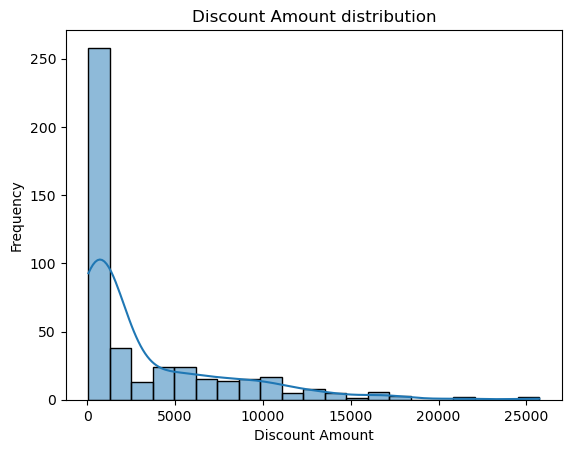

In [20]:
#Discount Amount 
sns.histplot(data=df_num, x="Discount Amount", kde=True)
plt.ylabel("Frequency")
plt.title("Discount Amount distribution")   
plt.show()

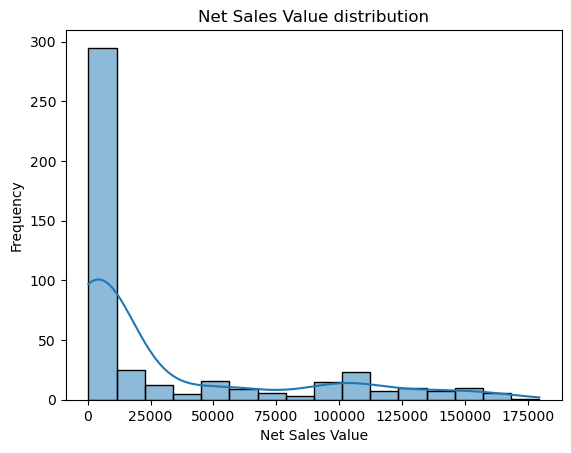

In [19]:
#Discount Amount 
sns.histplot(data=df_num, x="Net Sales Value", kde=True)
plt.ylabel("Frequency")
plt.title("Net Sales Value distribution")   
plt.show()

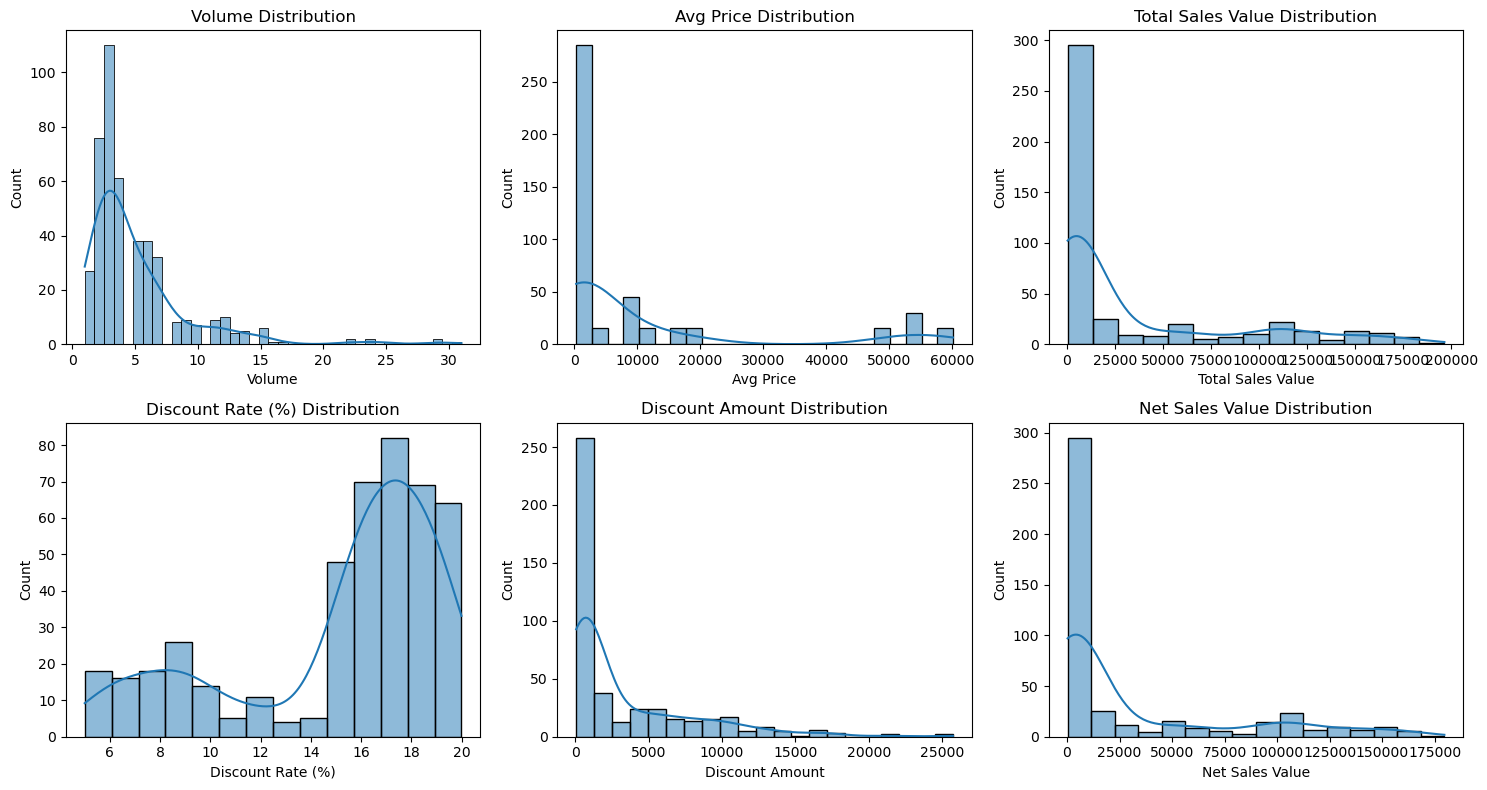

In [76]:
# Using Subplots to better visualize all the columns 
cols = ["Volume", "Avg Price", "Total Sales Value",
        "Discount Rate (%)", "Discount Amount", "Net Sales Value"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))  # 2 rows, 3 columns
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df_num, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

##### Observations
* Avg Price, Total Sales, Discount amount, Net sales Distributions are all rightly skewed suggesting few high value transactions and products exist and are given large discount amounts hence making the distribution positively skewed
* Volume distribution is also rightly skewed suggesting most sales are of small quantity only and very few involving large quantities
* only discount % distribution is balanced and concentrated between 15-20% meaning discounts given are uniform 

In [28]:
colms=["Volume","Avg Price", "Total Sales Value","Discount Rate (%)","Discount Amount","Net Sales Value"]

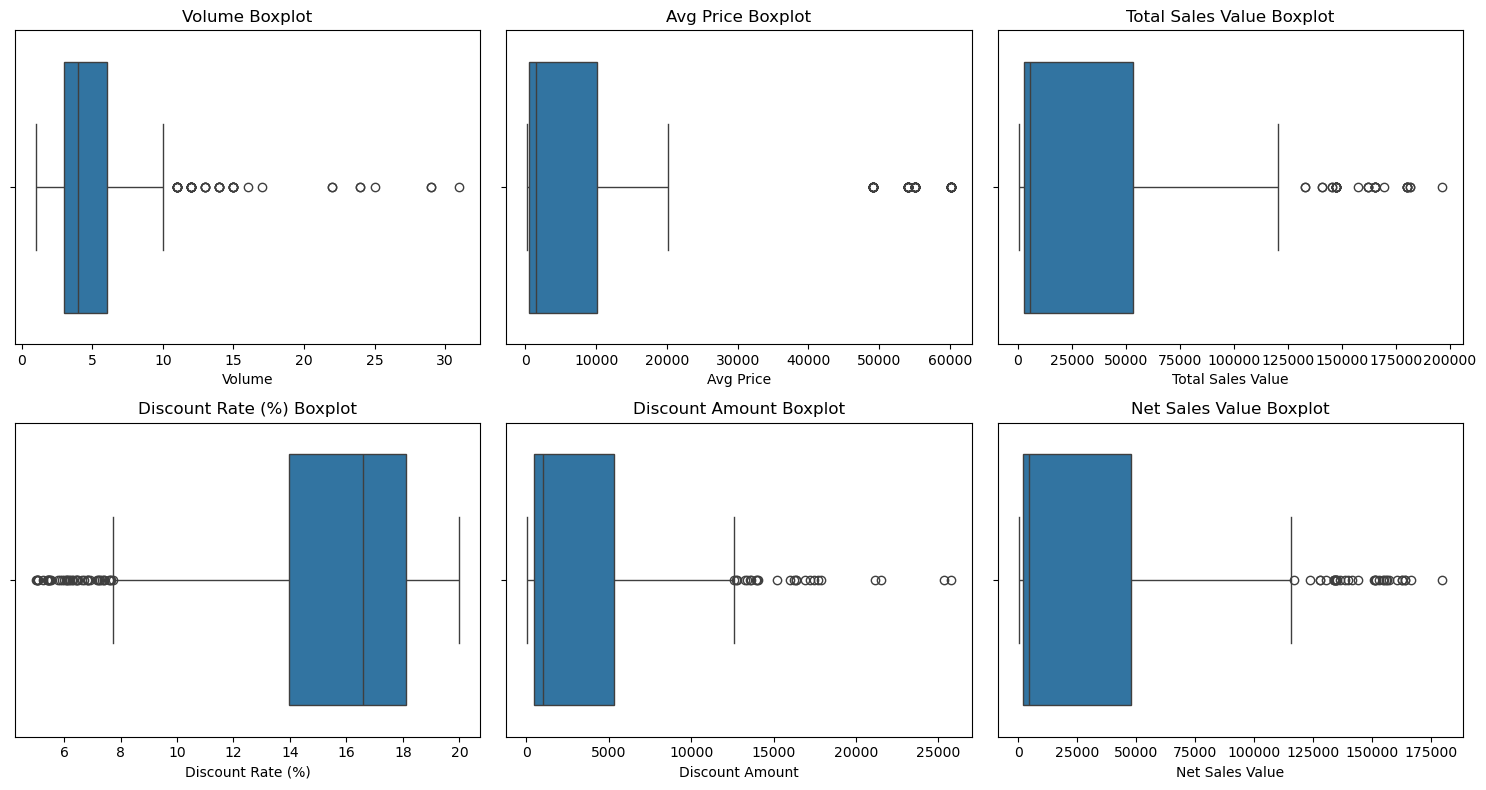

In [37]:
# now we plot boxplots to identify the outliers 
fig,axes = plt.subplots(2,3, figsize = (15,8))
axes = axes.flatten()
for i,colm in enumerate(colms):
    sns.boxplot(data=df_num, x=colm, ax = axes[i])
    axes[i].set_title(f"{colm} Boxplot")
plt.tight_layout()
plt.show()

##### Obseravtion
* Volume Boxplot shows presence of higher end outliers confirming that few high volume transactions exist
* Avg price also shows few commodities have higher than usual price and are outiers
* Total and net sales data also shows majority of the transactions are low value but few high value outliers are present
* Discount amount too has some higher value discounts
* while only disccount rate has some lower level outliers while majority of discount percentage is around 15-20%

#### Bar chart analysis for categorical data 


In [42]:
### First we make a dataset consisting of only categorical data
cat_cols = ["Date","Day","SKU","City","BU","Brand","Model"]
df_cat = df[cat_cols]
df_cat

,Date,Day,SKU,City,BU,Brand,Model
0,01-04-2021,Thursday,M01,C,Mobiles,RealU,RU-10
1,01-04-2021,Thursday,M02,C,Mobiles,RealU,RU-9 Plus
2,01-04-2021,Thursday,M03,C,Mobiles,YouM,YM-99
3,01-04-2021,Thursday,M04,C,Mobiles,YouM,YM-99 Plus
4,01-04-2021,Thursday,M05,C,Mobiles,YouM,YM-98
...,...,...,...,...,...,...,...
445,15-04-2021,Thursday,L06,C,Lifestyle,Jeera,M-Casuals
446,15-04-2021,Thursday,L07,C,Lifestyle,Viva,W-Western
447,15-04-2021,Thursday,L08,C,Lifestyle,Viva,W-Lounge
448,15-04-2021,Thursday,L09,C,Lifestyle,Jeera,M-Formals


<function matplotlib.pyplot.show(close=None, block=None)>

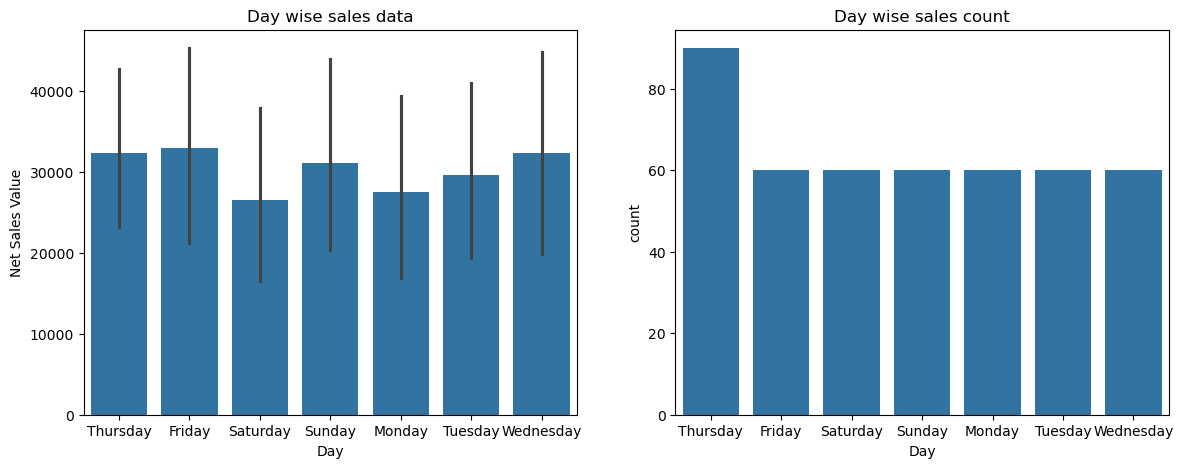

In [58]:
## creating bar chart for day column
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.barplot(x = "Day"  , y = "Net Sales Value", data = df , ax =axes[0])
axes[0].set_title("Day wise sales data")
sns.countplot(x="Day", data=df , ax =axes[1])
axes[1].set_title("Day wise sales count")
plt.show

#### The Revenue in each day is pretty well distributed but Thursday has particularly higher sales count suggesting people tend to buy products more on thursday

<function matplotlib.pyplot.show(close=None, block=None)>

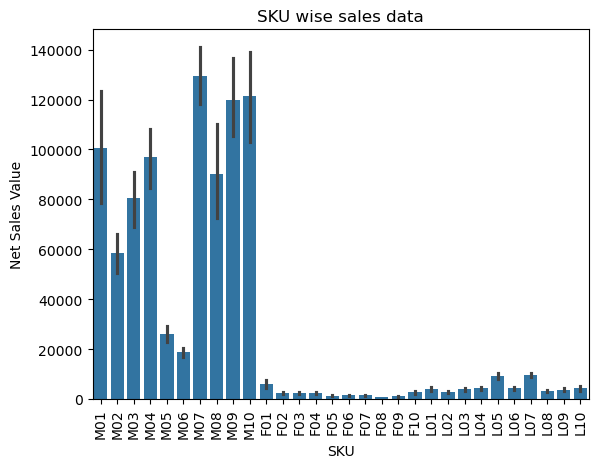

In [71]:
## creating bar chart for SKU column
sns.barplot(x = "SKU"  , y = "Net Sales Value", data = df )
plt.title("SKU wise sales data")
plt.xticks(rotation=90)
plt.show
## Omiting count since all the SKU's have the same count 

##### In SKU's M01 TO M10 drive the highest revenue and since each SKU has the same count these SKU's are high value and generate the bulk of the revenue

<function matplotlib.pyplot.show(close=None, block=None)>

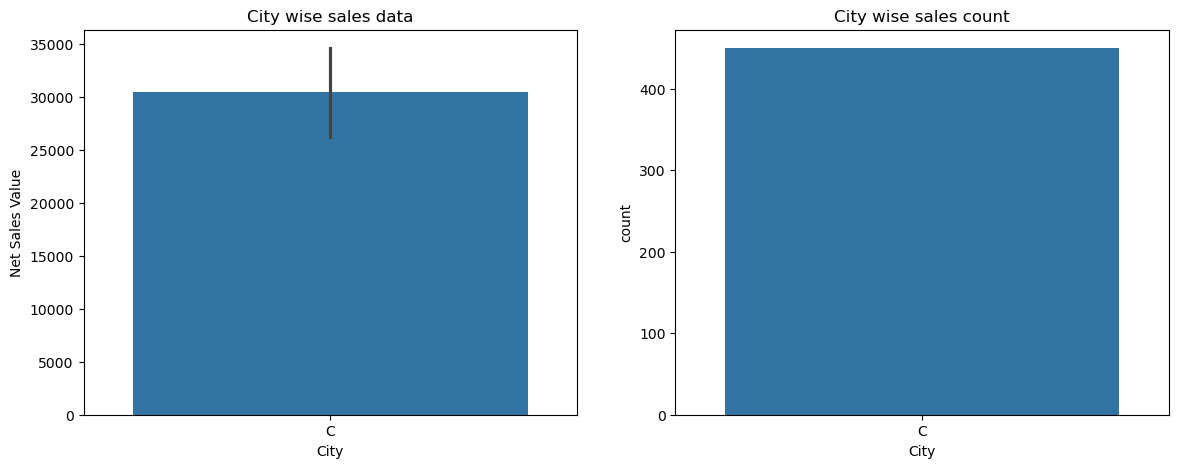

In [72]:
## creating bar chart for city column
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.barplot(x = "City"  , y = "Net Sales Value", data = df , ax =axes[0])
axes[0].set_title("City wise sales data")
sns.countplot(x="City", data=df , ax =axes[1])
axes[1].set_title("City wise sales count")
plt.show


#### since city has noly one category the bar plots are non consequential

<function matplotlib.pyplot.show(close=None, block=None)>

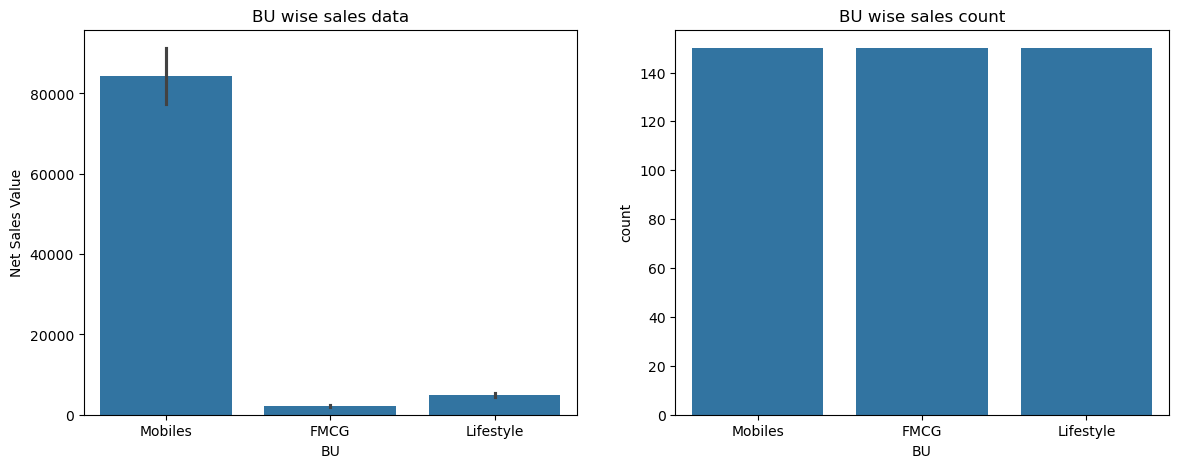

In [68]:
## creating bar chart for BU column
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.barplot(x = "BU"  , y = "Net Sales Value", data = df , ax =axes[0])
axes[0].set_title("BU wise sales data")
sns.countplot(x="BU", data=df , ax =axes[1])
axes[1].set_title("BU wise sales count")
plt.show

#### here again BU wise count data is same for all BU's hence doesnt tell us much but BU wise sales data tells us that Mobliles have the highest sales and are present in high volume

<function matplotlib.pyplot.show(close=None, block=None)>

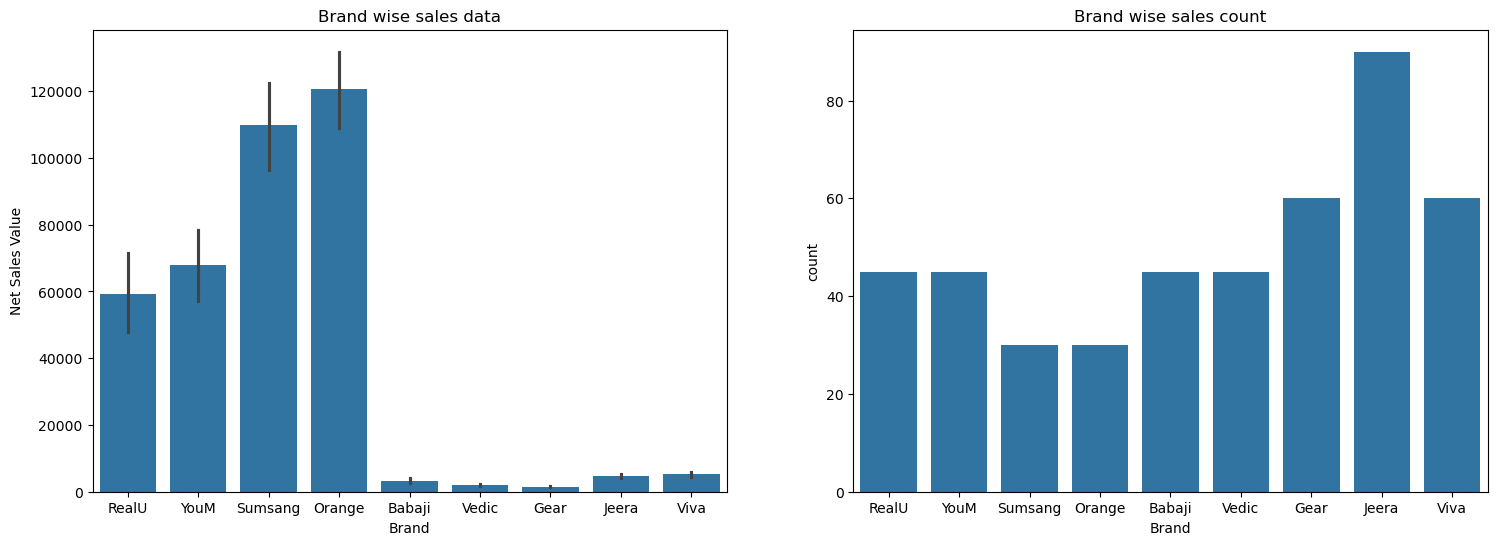

In [70]:
## creating bar chart for day column
fig, axes = plt.subplots(1,2, figsize=(18,6))
sns.barplot(x = "Brand"  , y = "Net Sales Value", data = df , ax =axes[0])
axes[0].set_title("Brand wise sales data")
sns.countplot(x="Brand", data=df , ax =axes[1])
axes[1].set_title("Brand wise sales count")
plt.show

#### Orange and Sumsang generate the highest total net sales value despite having the lowest sales counts, indicating they sell premium items. Conversely, brands like Jeera and Gear drive the highest sales volumes but contribute very little to overall revenue, suggesting they are low-cost, mass-market products.

<function matplotlib.pyplot.show(close=None, block=None)>

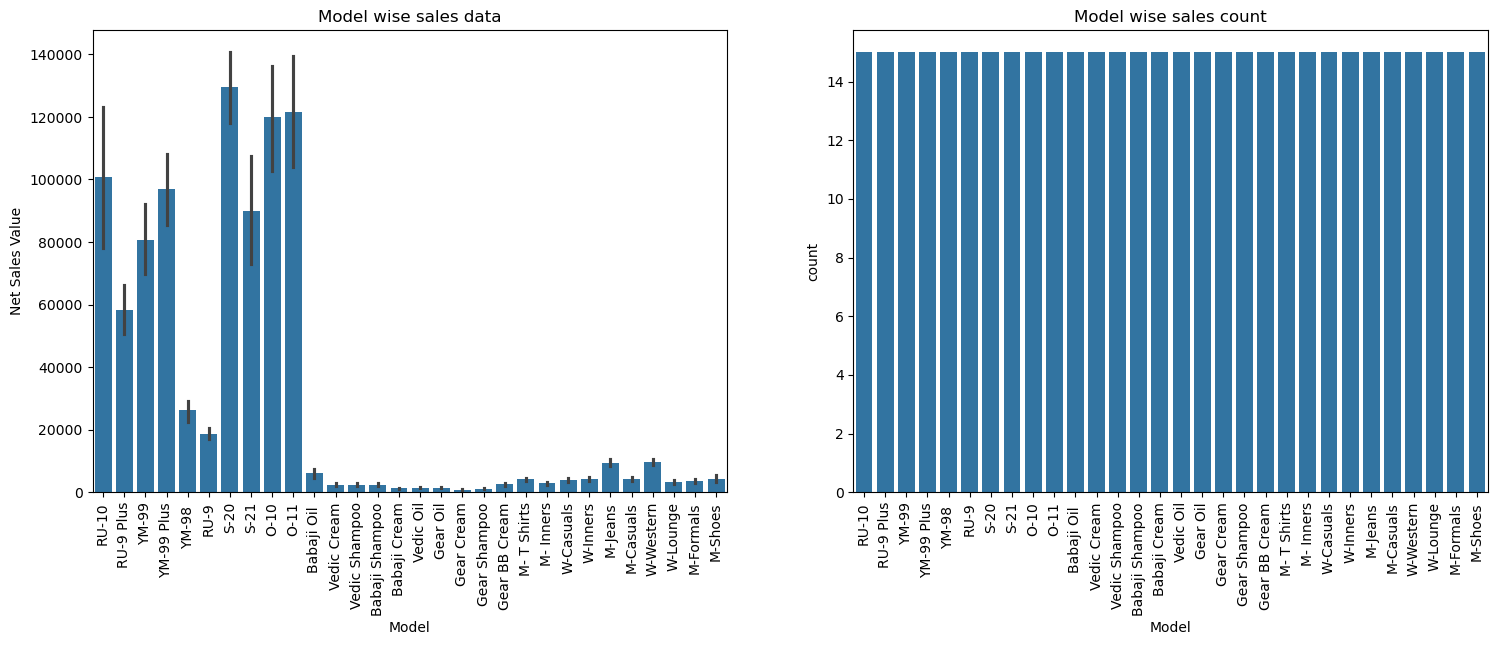

In [75]:
## creating bar chart for day column
fig, axes = plt.subplots(1,2, figsize=(18,6))
sns.barplot(x = "Model"  , y = "Net Sales Value", data = df , ax =axes[0])
axes[0].set_title("Model wise sales data")
axes[0].tick_params(axis='x', rotation=90)
sns.countplot(x="Model", data=df , ax =axes[1])
axes[1].set_title("Model wise sales count")
axes[1].tick_params(axis='x', rotation=90)
plt.show

#### Again its more than clear that the Mobile phone models drive the bulk of the Revenue while the food and other consumer goods are still sold in the same volume but are non consequential in terms of net Revenue 

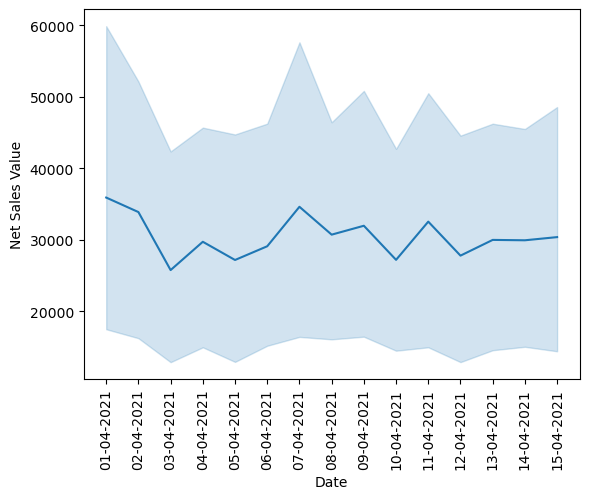

In [87]:
#### Line Chart to see how sales is over time
sns.lineplot(x ="Date" , y="Net Sales Value" , data = df)
plt.xticks(rotation = 90)
plt.show()